# 08 · Validación final de los modelos

**Objetivo:** comprobar con el conjunto de **validación** (el 30 % apartado en el notebook 01, que no se ha usado hasta ahora) que los tres modelos guardados funcionan con préstamos que **nunca han visto**, y que la **pérdida esperada** que calculan juntos se parece a la pérdida real:
1. Cargar la validación y los tres modelos **tal como los usará la API** (un solo archivo por modelo, con la preparación dentro).
2. Evaluar cada modelo por separado y comparar con lo que prometía la validación cruzada.
3. Juntar los tres en la **pérdida esperada** (PD × EAD × LGD × importe) y compararla con la pérdida real.
4. Comparar con **Lending Club**: ¿nuestra PD ordena el riesgo tan bien como su subrating? ¿Aporta algo dentro de cada nota?

**Cómo se trabaja:** igual que en los notebooks anteriores (observación → decisión → aplicación).

> **Regla general:** este notebook **no entrena ni ajusta nada**. Si algo saliera mal aquí, no se corrige mirando la validación (eso la convertiría en un segundo entrenamiento): se vuelve a los notebooks 05–07 y se razona el cambio con validación cruzada.

<a id="s0"></a>

## Registro de decisiones

| # | Tema | Decisión | Motivo principal |
|---|---|---|---|
| D1 | Uso de la validación | Una sola evaluación, sin ajustar nada | Es la única estimación honesta de cómo funcionarán los modelos con clientes nuevos |
| D2 | Criterio de aceptación | El resultado en validación debe quedar cerca del de la validación cruzada (a menos de 0,01 de AUC o un 2 % de RMSE) | Si se aleja mucho, los modelos estaban sobreajustados a entrenamiento |
| D3 | Pérdida real | (principal − amortizado − recuperado) de los impagados, mínimo 0 | Es la misma definición que la EAD × LGD de los notebooks 04–07, en euros |
| D4 | Resultado | Aceptar los tres modelos para la API, sin cambios | En validación rinden igual o mejor que en la validación cruzada, y la pérdida esperada de la cartera se desvía solo un 1,5 % de la real |

## Índice

- [Registro de decisiones](#s0)
- [1 · Importar librerías](#s1)
- [2 · Cargar la validación (D1)](#s2)
- [3 · Cargar los modelos](#s3)
- [4 · PD: discriminación y calibración (D2)](#s4)
  - [4.1 · AUC, Gini y KS frente a la validación cruzada](#s4-1)
  - [4.2 · Calibración](#s4-2)
  - [4.3 · Estabilidad por año](#s4-3)
- [5 · EAD y LGD](#s5)
- [6 · Pérdida esperada frente a pérdida real (D3)](#s6)
  - [6.1 · Toda la cartera](#s6-1)
  - [6.2 · Por tramos de riesgo](#s6-2)
- [7 · Comparación con Lending Club](#s7)
  - [7.1 · Por nota (A–G)](#s7-1)
  - [7.2 · ¿Aporta algo dentro de cada nota?](#s7-2)
- [8 · Conclusión (D4)](#s8)
- [9 · Resumen y próximos pasos](#s9)

> Cada sección empieza con una **franja azul**. Debajo de cada resultado hay una explicación de **qué se hace** y **qué se observa**.

<a id="s1"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">1 · IMPORTAR LIBRERÍAS</span>

</div>

In [1]:
# --- Librerías generales ----------------------------------------------------
from pathlib import Path          # rutas de archivos independientes del sistema operativo
import sys                        # añadir la carpeta 04_scripts a las rutas de Python
import warnings                   # silenciar avisos repetidos
import cloudpickle                # cargar los modelos guardados en los notebooks 05–07
import numpy as np                # cálculo numérico
import pandas as pd               # manejo de tablas (DataFrames)
import matplotlib.pyplot as plt   # gráficos
import seaborn as sns             # gráficos estadísticos sobre matplotlib
import sklearn                    # para comprobar la versión con la que se guardaron los modelos

# --- Métricas ------------------------------------------------------------------
from sklearn.metrics import roc_auc_score, roc_curve, log_loss, brier_score_loss
from sklearn.metrics import mean_absolute_error, root_mean_squared_error

# --- Preparación de los datos (04_scripts/preparacion.py) --------------------
# Solo se usa preparar_conjunto() para calcular los objetivos reales de la validación.
# Los modelos NO necesitan este módulo: llevan la preparación dentro (notebook 05, D9)
sys.path.insert(0, '../../04_scripts')
from preparacion import preparar_conjunto

# --- Opciones de visualización ------------------------------------------------
pd.set_option('display.float_format', lambda x: '%.4f' % x)  # 4 decimales
pd.set_option('display.max_columns', 60)
sns.set_theme(style='whitegrid')
warnings.filterwarnings('ignore', category=UserWarning)
warnings.filterwarnings('ignore', category=FutureWarning)

print(f"✅ Librerías importadas correctamente (scikit-learn {sklearn.__version__}, pandas {pd.__version__})")

✅ Librerías importadas correctamente (scikit-learn 1.9.1, pandas 3.0.6)


**Qué se hace:** se importan las librerías: `cloudpickle` para cargar los modelos, las métricas de los notebooks 05–07 y `preparar_conjunto()` para calcular los objetivos reales (impago, EAD, LGD) de la validación.

**Qué se observa:** el mensaje muestra las versiones de `scikit-learn` y `pandas`; en la sección 3 se comparan con las versiones con las que se guardaron los modelos.

<a id="s2"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">2 · CARGAR LA VALIDACIÓN (D1)</span>

</div>

In [2]:
# Rutas (relativas a la carpeta de este notebook: 03_notebooks/es)
RUTA_VALIDACION = Path('../../02_datos/02_Validacion')
RUTA_ENTRENAMIENTO = Path('../../02_datos/03_Entrenamiento')
RUTA_MODELOS = Path('../../05_modelos')

# Validación ORIGINAL (notebook 01): mismo formato que train.pkl
validacion_original = pd.read_pickle(RUTA_VALIDACION / 'validacion.pkl')

# Misma población y objetivos que en entrenamiento: quita las viviendas NONE/OTHER/ANY y calcula impago, EAD y LGD
val = preparar_conjunto(validacion_original)

print(f"Préstamos en validación: {len(validacion_original):,} → {len(val):,} tras quitar viviendas fuera de la población "
      f"({len(validacion_original) - len(val)} préstamos)")
print(f"Tasa de impago: {val['impago'].mean():.2%} · impagados con EAD: {val['ead'].notna().sum():,} · con LGD: {val['lgd'].notna().sum():,}")

Préstamos en validación: 190,059 → 190,033 tras quitar viviendas fuera de la población (26 préstamos)
Tasa de impago: 14.85% · impagados con EAD: 28,218 · con LGD: 28,218


**Qué se hace:** se carga el conjunto de validación original y se le aplica `preparar_conjunto()`, igual que al entrenamiento en los notebooks 05–07: se quitan las viviendas fuera de la población del modelo y se calculan los tres objetivos reales.

**Qué se observa:** quedan **190.033 préstamos** (se quitan 26 con vivienda NONE, OTHER o ANY) con una tasa de impago del **14,85 %**, la misma que en entrenamiento gracias a la partición estratificada. Hay **28.218 impagados**, y todos tienen deuda pendiente, así que todos tienen EAD y LGD.

> **Decisión D1 · La validación se usa una sola vez y no se ajusta nada con ella.**
> - **Por qué:** todas las decisiones (variables, modelo, hiperparámetros) se tomaron con validación cruzada dentro de entrenamiento. La validación es la **única** estimación que no ha influido en ninguna decisión; si se usara para corregir algo, dejaría de serlo.
> - **Qué se hace si algo falla:** se vuelve a los notebooks 05–07 y se razona el cambio con validación cruzada, no con estos resultados.
> - **Es una partición aleatoria** (notebook 01, D12): mismos años (2012–2015) y misma tasa de impago que entrenamiento. Mide si los modelos **generalizan** a clientes nuevos parecidos, no si aguantan un cambio de época (eso se vigila en la sección 4.3).

<a id="s3"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">3 · CARGAR LOS MODELOS</span>

</div>

In [3]:
def cargar_modelo(nombre):
    """Carga el paquete guardado por los notebooks 05–07 (modelo + metadatos)."""
    with open(RUTA_MODELOS / f'modelo_{nombre}.pkl', 'rb') as archivo:
        return cloudpickle.load(archivo)

paquetes = {nombre: cargar_modelo(nombre) for nombre in ['pd', 'ead', 'lgd']}

# Resumen de cada modelo y comprobación de versiones
pd.DataFrame({
    nombre: {
        'familia': p['familia'],
        'hiperparametros': p['hiperparametros'],
        'n_variables': len(p['variables']),
        'sklearn al guardar': p['version_sklearn'],
        'sklearn ahora': sklearn.__version__,
        'misma versión': p['version_sklearn'] == sklearn.__version__,
    } for nombre, p in paquetes.items()
}).T

,familia,hiperparametros,n_variables,sklearn al guardar,sklearn ahora,misma versión
pd,HistGradientBoosting,"learning_rate=0.05, max_leaf_nodes=63, min_sam...",15,1.9.1,1.9.1,True
ead,Ridge,alpha=100,16,1.9.1,1.9.1,True
lgd,sin variables,strategy=mean,16,1.9.1,1.9.1,True


**Qué se hace:** se cargan los tres paquetes de `05_modelos/` y se muestra qué modelo hay en cada uno y con qué versión de `scikit-learn` se guardó.

**Qué se observa:** los tres se guardaron con `scikit-learn` 1.9.1, la misma versión que se usa ahora, así que se pueden cargar con seguridad. La PD es el *gradient boosting* de 63 hojas, la EAD es Ridge (`alpha` 100) y la LGD es la media de entrenamiento. Se cargan **sin necesitar `preparacion.py`**, porque el código va dentro del archivo.

In [4]:
# Columnas originales que espera cada pipeline (las mismas para los tres)
COLUMNAS_ENTRADA = paquetes['pd']['columnas_entrada']
X_val = val[COLUMNAS_ENTRADA]

# Predicciones de los tres modelos para TODOS los préstamos de validación.
# Cada pipeline hace él mismo la preparación (limpieza, imputación, recortes...) con lo aprendido en entrenamiento
val['pd_predicha'] = paquetes['pd']['modelo'].predict_proba(X_val)[:, 1]
val['ead_predicha'] = paquetes['ead']['modelo'].predict(X_val).clip(0, 1)   # 'recortar_0_1': la EAD está entre 0 y 1
val['lgd_predicha'] = paquetes['lgd']['modelo'].predict(X_val).clip(0, 1)

val[['pd_predicha', 'ead_predicha', 'lgd_predicha']].describe().T

,count,mean,std,min,25%,50%,75%,max
pd_predicha,190033.0000,0.1485,0.0814,0.0093,0.0866,0.1348,0.1970,0.5788
ead_predicha,190033.0000,0.5753,0.0472,0.4072,0.5448,0.5692,0.5965,0.8500
lgd_predicha,190033.0000,0.8691,0.0000,0.8691,0.8691,0.8691,0.8691,0.8691


**Qué se hace:** se pasan las 19 columnas originales de la validación a los tres *pipelines* y se guardan sus predicciones. La EAD y la LGD se predicen para **todos** los préstamos (también los que no impagaron), porque la pérdida esperada de un préstamo nuevo necesita las tres aunque todavía no se sepa si impagará.

**Qué se observa:** 
- **PD:** media del **14,85 %**, igual que la tasa real de impago, y va del 0,9 % al 58 %.
- **EAD:** entre 0,41 y 0,85, con media 0,575. Es algo menor que la EAD media de los impagados (0,593), porque en la cartera completa hay menos préstamos a 60 cuotas (7 %) que entre los impagados (12 %), y a 60 cuotas queda más deuda pendiente.
- **LGD:** 0,869 para todos (notebook 07, D4).

<a id="s4"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">4 · PD: DISCRIMINACIÓN Y CALIBRACIÓN (D2)</span>

</div>

<a id="s4-1"></a>

### 4.1 · AUC, Gini y KS frente a la validación cruzada

,AUC,Gini,KS,log_loss,Brier
modelo · validación cruzada,0.6767,0.3533,0.2563,0.3947,0.1200
modelo · validación,0.6782,0.3564,0.2573,0.3942,0.1199
subrating · validación,0.6701,0.3401,0.2487,NaN,NaN


AUC en validación − AUC en validación cruzada: +0.0015
Ventaja sobre el subrating en validación: +0.0081


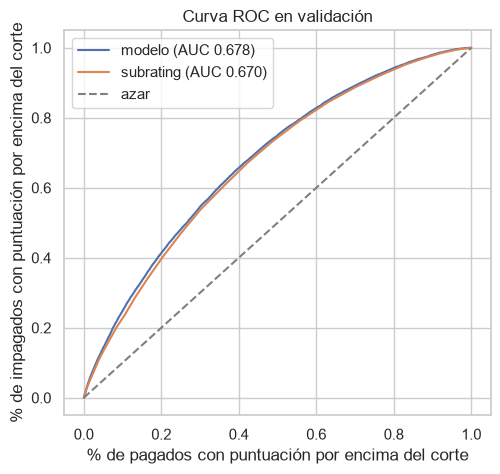

In [5]:
def discriminacion(y_real, puntuacion):
    """AUC, Gini y KS de una puntuación de riesgo (igual que en el notebook 05)."""
    auc = roc_auc_score(y_real, puntuacion)
    fpr, tpr, _ = roc_curve(y_real, puntuacion)
    return {'AUC': auc, 'Gini': 2 * auc - 1, 'KS': np.max(tpr - fpr)}

y_val = val['impago']
puntuacion_subrating = val['subrating'].cat.codes   # A1 = 0, A2 = 1... (más alto = más riesgo)

cv = paquetes['pd']['metricas_validacion_cruzada']
tabla_pd = pd.DataFrame({
    'modelo · validación cruzada': {'AUC': cv['AUC'], 'Gini': cv['Gini'], 'KS': cv['KS'],
                                    'log_loss': cv['log_loss'], 'Brier': cv['Brier']},
    'modelo · validación': {**discriminacion(y_val, val['pd_predicha']),
                            'log_loss': log_loss(y_val, val['pd_predicha']),
                            'Brier': brier_score_loss(y_val, val['pd_predicha'])},
    'subrating · validación': discriminacion(y_val, puntuacion_subrating),
}).T
display(tabla_pd)

diferencia_auc = tabla_pd.loc['modelo · validación', 'AUC'] - tabla_pd.loc['modelo · validación cruzada', 'AUC']
print(f"AUC en validación − AUC en validación cruzada: {diferencia_auc:+.4f}")
print(f"Ventaja sobre el subrating en validación: {tabla_pd.loc['modelo · validación', 'AUC'] - tabla_pd.loc['subrating · validación', 'AUC']:+.4f}")

# Curvas ROC del modelo y del subrating en validación
fig, eje = plt.subplots(figsize=(5.5, 5))
for nombre, puntuacion in [('modelo', val['pd_predicha']), ('subrating', puntuacion_subrating)]:
    fpr, tpr, _ = roc_curve(y_val, puntuacion)
    eje.plot(fpr, tpr, label=f"{nombre} (AUC {roc_auc_score(y_val, puntuacion):.3f})")
eje.plot([0, 1], [0, 1], color='grey', linestyle='--', label='azar')
eje.set_xlabel('% de pagados con puntuación por encima del corte')
eje.set_ylabel('% de impagados con puntuación por encima del corte')
eje.set_title('Curva ROC en validación')
eje.legend()
plt.show()

**Qué se hace:** AUC, Gini, KS, *log-loss* y Brier del modelo en validación, junto a los que dio la validación cruzada (guardados en el paquete) y los del subrating de Lending Club en estos mismos préstamos.

**Qué se observa:** el AUC en validación es **0,6782**, incluso un poco **mejor** que en la validación cruzada (0,6767, +0,0015). Gini (0,356), KS (0,257), *log-loss* (0,3942) y Brier (0,1199) también coinciden. El modelo **no estaba sobreajustado**. Además sigue **superando al subrating** por la misma distancia que en entrenamiento (+0,008: 0,6782 frente a 0,6701).

> **Decisión D2 · Criterio de aceptación: el resultado en validación debe quedar cerca del de la validación cruzada.**
> - **Umbrales:** a menos de **0,01 de AUC** en la PD y a menos de un **2 % de RMSE** en la EAD y la LGD. Son unas 5–10 veces el error estándar de la validación cruzada (0,001 de AUC): una diferencia mayor no sería azar.
> - **Por qué no se exige que gane al subrating:** el objetivo era igualar a Lending Club con los datos del formulario; ganarle es un extra. Lo que no se puede aceptar es que el modelo empeore fuera de entrenamiento.
> - **Alternativa:** un contraste estadístico formal (por ejemplo, DeLong para comparar AUC). Con 190.000 préstamos cualquier diferencia mínima sería "significativa"; un umbral de negocio es más útil.

<a id="s4-2"></a>

### 4.2 · Calibración

Igual que en el notebook 05 (D8): se agrupan los préstamos en 10 tramos según la PD predicha y se compara la PD media predicha con la tasa real de impago.

,n,pd_predicha,tasa_real,diferencia
decil_pd,,,,
1,19004,0.0391,0.0376,0.0014
2,19003,0.0661,0.0645,0.0016
3,19003,0.0866,0.0844,0.0022
4,19003,0.1055,0.1082,-0.0027
5,19004,0.1247,0.1261,-0.0014
6,19003,0.1457,0.1486,-0.0029
7,19003,0.1692,0.1742,-0.0050
8,19003,0.1973,0.1941,0.0032
9,19003,0.2355,0.2341,0.0014


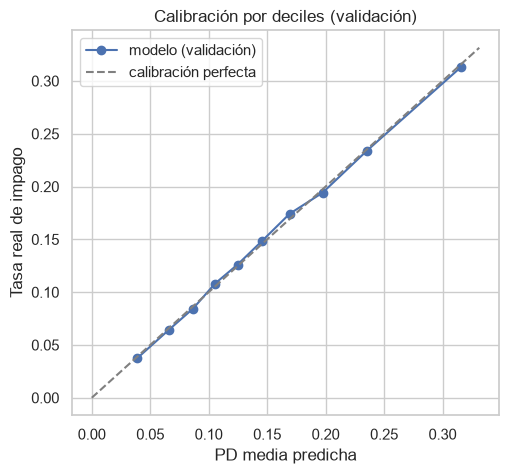

In [6]:
val['decil_pd'] = pd.qcut(val['pd_predicha'], 10, labels=range(1, 11))
calibracion = val.groupby('decil_pd', observed=True).agg(
    n=('impago', 'size'), pd_predicha=('pd_predicha', 'mean'), tasa_real=('impago', 'mean'))
calibracion['diferencia'] = calibracion['pd_predicha'] - calibracion['tasa_real']
display(calibracion)

fig, eje = plt.subplots(figsize=(5.5, 5))
eje.plot(calibracion['pd_predicha'], calibracion['tasa_real'], marker='o', label='modelo (validación)')
limite = calibracion[['pd_predicha', 'tasa_real']].max().max() * 1.05
eje.plot([0, limite], [0, limite], color='grey', linestyle='--', label='calibración perfecta')
eje.set_xlabel('PD media predicha')
eje.set_ylabel('Tasa real de impago')
eje.set_title('Calibración por deciles (validación)')
eje.legend()
plt.show()

**Qué se hace:** tabla y gráfico de calibración por deciles de PD predicha, ahora con préstamos que el modelo no ha visto.

**Qué se observa:** la calibración se mantiene: la PD predicha y la tasa real coinciden en todos los deciles, con una diferencia máxima de **0,5 puntos** (decil 7: 16,9 % frente a 17,4 %). El riesgo real va del **3,8 %** en el decil 1 al **31,3 %** en el decil 10.

<a id="s4-3"></a>

### 4.3 · Estabilidad por año

La validación tiene préstamos de 2012 a 2015. Si el AUC o la calibración cambiaran mucho de un año a otro, el modelo sería frágil ante cambios en el tipo de cliente o en la economía. En el notebook 03 (D20) se vio que `sector_empleo` cambió de definición a finales de 2013: aquí se ve si eso afecta.

In [7]:
val['año'] = val['fecha_concesion'].dt.year
por_año = val.groupby('año').apply(lambda g: pd.Series({
    'n': len(g),
    'tasa_real': g['impago'].mean(),
    'pd_predicha': g['pd_predicha'].mean(),
    'AUC_modelo': roc_auc_score(g['impago'], g['pd_predicha']),
    'AUC_subrating': roc_auc_score(g['impago'], g['subrating'].cat.codes),
}), include_groups=False)
por_año['n'] = por_año['n'].astype(int)
por_año

,n,tasa_real,pd_predicha,AUC_modelo,AUC_subrating
año,,,,,
2012,15723,0.1642,0.1595,0.6923,0.6594
2013,40362,0.1549,0.1652,0.6865,0.6703
2014,49101,0.1371,0.1424,0.6702,0.6632
2015,84847,0.1491,0.1421,0.6756,0.6775


**Qué se hace:** para cada año de concesión: número de préstamos, tasa real de impago, PD media predicha y AUC del modelo y del subrating.

**Qué se observa:** 
- **Discriminación estable:** el AUC del modelo está entre **0,670** (2014) y **0,692** (2012) y supera al subrating en 2012, 2013 y 2014. En 2015 quedan prácticamente empatados (0,6756 frente a 0,6775).
- El **subrating mejora con los años** (de 0,659 a 0,678): Lending Club fue afinando su modelo; el nuestro se entrenó con todos los años a la vez.
- **Calibración por año:** el modelo no sabe en qué año está, así que predice parecido todos los años. Sobreestima 2013 (16,5 % frente a 15,5 %) y subestima 2015 (14,2 % frente a 14,9 %), siempre por **menos de 1,1 puntos**.
- No se ve ningún salto a finales de 2013 por el cambio de definición de `sector_empleo` (notebook 03, D20).

<a id="s5"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">5 · EAD Y LGD</span>

</div>

La EAD y la LGD solo se pueden comprobar en los préstamos que **impagaron** (en los demás no hay deuda pendiente que medir). Se comparan con lo que prometía la validación cruzada y con la predicción sin modelo de los notebooks 06 y 07, calculada con **entrenamiento**: la media de cada plazo para la EAD y la media global para la LGD.

In [8]:
def errores(y_real, prediccion):
    """MAE, RMSE y sesgo de una predicción (igual que en los notebooks 06 y 07)."""
    return {'MAE': mean_absolute_error(y_real, prediccion),
            'RMSE': root_mean_squared_error(y_real, prediccion),
            'sesgo': np.mean(prediccion) - np.mean(y_real)}

# Predicciones sin modelo aprendidas con ENTRENAMIENTO (listones de los notebooks 06 y 07)
entrenamiento = preparar_conjunto(pd.read_pickle(RUTA_ENTRENAMIENTO / 'train.pkl'))
ead_por_plazo = entrenamiento.groupby('num_cuotas')['ead'].mean()   # EAD media de cada plazo
lgd_media = entrenamiento['lgd'].mean()                             # LGD media global

filas = {}
for objetivo, liston_nombre, liston in [
        ('ead', 'media de cada plazo', lambda d: d['num_cuotas'].map(ead_por_plazo)),
        ('lgd', 'media global', lambda d: np.full(len(d), lgd_media))]:
    con_dato = val[val[objetivo].notna()]                              # solo préstamos con objetivo conocido
    filas[(objetivo.upper(), 'modelo · validación cruzada')] = {
        k: paquetes[objetivo]['metricas_validacion_cruzada'][k] for k in ['MAE', 'RMSE', 'sesgo']}
    filas[(objetivo.upper(), 'modelo · validación')] = errores(con_dato[objetivo], con_dato[f'{objetivo}_predicha'])
    filas[(objetivo.upper(), f'{liston_nombre} · validación')] = errores(con_dato[objetivo], liston(con_dato))

tabla_ead_lgd = pd.DataFrame(filas).T
tabla_ead_lgd['RMSE_vs_validacion_cruzada_%'] = [
    100 * (fila['RMSE'] / tabla_ead_lgd.loc[(obj, 'modelo · validación cruzada'), 'RMSE'] - 1)
    for (obj, _), fila in tabla_ead_lgd.iterrows()]
tabla_ead_lgd

MAE   RMSE   sesgo  \
EAD modelo · validación cruzada      0.1963 0.2352 -0.0000   
    modelo · validación              0.1968 0.2352 -0.0007   
    media de cada plazo · validación 0.1994 0.2377 -0.0005   
LGD modelo · validación cruzada      0.0940 0.1478 -0.0000   
    modelo · validación              0.0935 0.1470 -0.0015   
    media global · validación        0.0935 0.1470 -0.0015   

                                      RMSE_vs_validacion_cruzada_%  
EAD modelo · validación cruzada                             0.0000  
    modelo · validación                                    -0.0079  
    media de cada plazo · validación                        1.0430  
LGD modelo · validación cruzada                             0.0000  
    modelo · validación                                    -0.5223  
    media global · validación                              -0.5223

**Qué se hace:** MAE, RMSE y sesgo de la EAD (Ridge) y de la LGD (media de entrenamiento) en validación, frente a la validación cruzada y a la predicción sin modelo. La última columna es cuánto cambia el RMSE respecto al de la validación cruzada del modelo (en %).

**Qué se observa:** 
- **EAD:** el RMSE en validación (**0,2352**) es **idéntico** al de la validación cruzada, y el sesgo es mínimo (−0,0007). Sigue ganando a la media de cada plazo (0,2377), un 1 % mejor.
- **LGD:** el RMSE es incluso un **0,5 % mejor** (0,1470). El sesgo de −0,0015 es la diferencia entre la LGD media de validación (0,8706) y la de entrenamiento (0,869). El modelo y la media global coinciden porque el modelo **es** la media.
- Los dos quedan muy dentro del criterio de D2 (menos de un 2 % de cambio en el RMSE).

In [9]:
# Igual que en el notebook 06 (sección 8.2): ¿ordena la EAD? Media predicha y real por deciles de la predicción
impagados = val[val['ead'].notna()].copy()
impagados['decil_ead'] = pd.qcut(impagados['ead_predicha'].rank(method='first'), 10, labels=range(1, 11))
impagados.groupby('decil_ead', observed=True).agg(
    n=('ead', 'size'), ead_predicha=('ead_predicha', 'mean'), ead_real=('ead', 'mean'))

,n,ead_predicha,ead_real
decil_ead,,,
1,2822,0.5210,0.5194
2,2822,0.5450,0.5531
3,2822,0.5581,0.5602
4,2821,0.5686,0.5725
5,2822,0.5784,0.5763
6,2822,0.5882,0.5908
7,2821,0.5998,0.5977
8,2822,0.6150,0.6156
9,2822,0.6450,0.6469


**Qué se hace:** EAD media predicha y real en cada decil de la predicción, en los impagados de validación.

**Qué se observa:** la EAD **ordena igual que en entrenamiento**: la real sube de **0,52** en el decil 1 a **0,70** en el decil 10, y la predicha coincide con la real en todos los deciles (diferencias de menos de 0,01).

<a id="s6"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">6 · PÉRDIDA ESPERADA FRENTE A PÉRDIDA REAL (D3)</span>

</div>

La **pérdida esperada** (PE) de un préstamo es lo que se espera perder **de media** con él:

**PE = PD × EAD × LGD × importe**

- **PD:** probabilidad de que impague.
- **EAD:** fracción del importe que quedará pendiente si impaga.
- **LGD:** fracción de esa deuda pendiente que no se recuperará.

Para un préstamo concreto la pérdida real es 0 (si paga) o un importe grande (si impaga), así que la PE no acierta préstamo a préstamo: se comprueba **sumando** muchos préstamos, en toda la cartera y por tramos.

In [10]:
# Pérdida esperada de cada préstamo (en dólares, la moneda de Lending Club)
val['perdida_esperada'] = val['pd_predicha'] * val['ead_predicha'] * val['lgd_predicha'] * val['principal']

# Pérdida real: lo pendiente al impagar menos lo recuperado = principal × EAD × LGD (0 si pagó)
val['perdida_real'] = (val['principal'] * val['ead'] * val['lgd']).fillna(0)

print(f"Ejemplo: préstamo de {val['principal'].iloc[0]:,.0f} $ con PD {val['pd_predicha'].iloc[0]:.1%}, "
      f"EAD {val['ead_predicha'].iloc[0]:.2f} y LGD {val['lgd_predicha'].iloc[0]:.3f} "
      f"→ pérdida esperada {val['perdida_esperada'].iloc[0]:,.0f} $")

Ejemplo: préstamo de 6,000 $ con PD 7.2%, EAD 0.54 y LGD 0.869 → pérdida esperada 200 $


**Qué se hace:** se calcula la pérdida esperada de cada préstamo con las tres predicciones y la pérdida real con lo que pasó de verdad.

**Qué se observa:** en el primer préstamo de validación (6.000 $, PD 7,2 %, EAD 0,54 y LGD 0,869) se espera perder **200 $**, un 3,3 % de lo prestado. Si impaga, perderá mucho más; si paga, nada. La pérdida esperada es la media entre esos dos escenarios, ponderada por su probabilidad.

> **Decisión D3 · La pérdida real es (principal − amortizado − recuperado) de los impagados, con mínimo 0.**
> - **Por qué:** es exactamente principal × EAD × LGD con las definiciones de los notebooks 04–07, así que se compara lo mismo que se ha modelizado.
> - **Lo que no incluye:** los intereses no cobrados, las comisiones de cobro y el valor temporal del dinero. Un banco los añadiría; aquí se deja fuera para que la comparación sea directa con los modelos.
> - **Impagados sin deuda pendiente** (LGD nula; en entrenamiento había 2 y en validación ninguno): cuentan como pérdida 0.

<a id="s6-1"></a>

### 6.1 · Toda la cartera

In [11]:
total_esperada = val['perdida_esperada'].sum()
total_real = val['perdida_real'].sum()
total_prestado = val['principal'].sum()

cartera = pd.DataFrame({
    'millones de $': [total_prestado / 1e6, total_esperada / 1e6, total_real / 1e6],
    '% del importe prestado': [100, 100 * total_esperada / total_prestado, 100 * total_real / total_prestado],
}, index=['importe prestado', 'pérdida esperada', 'pérdida real'])
display(cartera)
print(f"Pérdida esperada / pérdida real: {total_esperada / total_real:.3f}")

,millones de $,% del importe prestado
importe prestado,2510.1887,100.0000
pérdida esperada,194.6363,7.7539
pérdida real,197.6587,7.8743


Pérdida esperada / pérdida real: 0.985


**Qué se hace:** se suman la pérdida esperada y la real de los 190.000 préstamos de validación y se comparan con el importe prestado.

**Qué se observa:** en los 2.510 millones de dólares prestados, la pérdida esperada es de **194,6 millones (7,75 %)** y la real de **197,7 millones (7,87 %)**. Los tres modelos juntos **aciertan la pérdida de la cartera con un error del 1,5 %** (la subestiman ligeramente).

<a id="s6-2"></a>

### 6.2 · Por tramos de riesgo

Que el total cuadre no basta: los errores de unos préstamos podrían compensarse con los de otros. Se repite la comparación en los 10 deciles de PD predicha (sección 4.2).

,PE_%,real_%,esperada/real
decil_pd,,,
1,1.8218,1.7280,1.0543
2,3.1453,2.9671,1.0601
3,4.1904,4.1546,1.0086
4,5.1698,5.3157,0.9725
5,6.1933,6.5403,0.9469
6,7.3365,7.4945,0.9789
7,8.6564,8.9961,0.9622
8,10.2622,10.3107,0.9953
9,12.5751,12.7593,0.9856


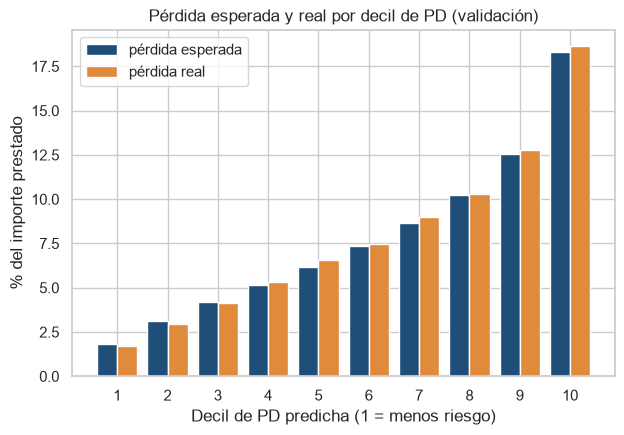

In [12]:
por_decil = val.groupby('decil_pd', observed=True).agg(
    prestado=('principal', 'sum'), perdida_esperada=('perdida_esperada', 'sum'), perdida_real=('perdida_real', 'sum'))
por_decil['PE_%'] = 100 * por_decil['perdida_esperada'] / por_decil['prestado']   # pérdida esperada en % de lo prestado
por_decil['real_%'] = 100 * por_decil['perdida_real'] / por_decil['prestado']
por_decil['esperada/real'] = por_decil['perdida_esperada'] / por_decil['perdida_real']
display(por_decil[['PE_%', 'real_%', 'esperada/real']])

fig, eje = plt.subplots(figsize=(7, 4.5))
x = por_decil.index.astype(int)
eje.bar(x - 0.2, por_decil['PE_%'], width=0.4, label='pérdida esperada', color='#1f4e79')
eje.bar(x + 0.2, por_decil['real_%'], width=0.4, label='pérdida real', color='#e08a3c')
eje.set_xticks(x)
eje.set_xlabel('Decil de PD predicha (1 = menos riesgo)')
eje.set_ylabel('% del importe prestado')
eje.set_title('Pérdida esperada y real por decil de PD (validación)')
eje.legend()
plt.show()

**Qué se hace:** pérdida esperada y real, en % de lo prestado, en cada decil de PD, y su cociente (1 = acierta).

**Qué se observa:** 
- La pérdida esperada **sube igual que la real** en los deciles: del **1,8 %** de lo prestado en el decil 1 al **18,3 %** en el decil 10 (real: del 1,7 % al 18,6 %).
- El cociente esperada / real está entre **0,95 y 1,06** en todos los deciles: el error de cada tramo no pasa del 6 %.
- Sobreestima un poco los dos tramos más seguros (+5 % y +6 %) y subestima un poco los centrales (hasta −5 %).

<a id="s7"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">7 · COMPARACIÓN CON LENDING CLUB</span>

</div>

Lending Club no publica su PD, pero sí la **nota** (A–G) de cada préstamo. Se compara de dos formas:
1. **Por nota:** ¿nuestra PD media en cada nota coincide con la tasa real de impago de esa nota?
2. **Dentro de cada nota:** si nuestro modelo solo copiara la nota, su AUC dentro de cada nota sería 0,5. Si es mayor, **aporta información que la nota no tiene**.

<a id="s7-1"></a>

### 7.1 · Por nota (A–G)

,n,tasa_real,pd_predicha,pd_min,pd_max,PE_pct,real_pct
nota,,,,,,,
A,40252,0.0553,0.0785,0.0301,0.1405,3.6293,2.3653
B,62203,0.1127,0.1302,0.0632,0.2107,6.3337,5.3546
C,51363,0.1826,0.1749,0.0905,0.2712,9.1985,9.4809
D,24414,0.2407,0.2038,0.1087,0.3079,11.2144,14.0109
E,8591,0.2995,0.2418,0.1323,0.3591,14.6167,18.7797
F,2738,0.3550,0.2847,0.1608,0.4134,18.6254,22.6544
G,472,0.3835,0.3225,0.1965,0.4467,20.7112,24.7383


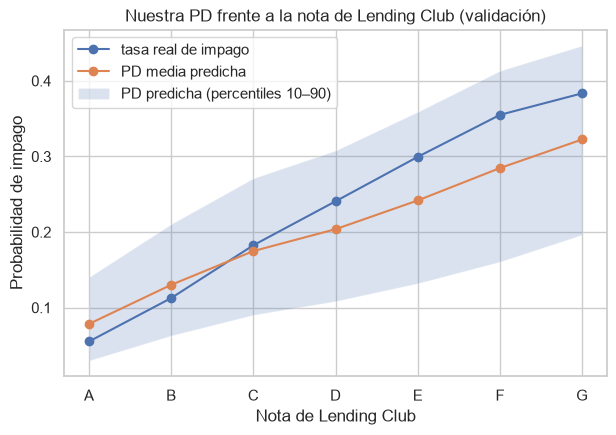

In [13]:
val['nota'] = val['subrating'].astype(str).str[0]   # A1 → A
por_nota = val.groupby('nota').agg(
    n=('impago', 'size'),
    tasa_real=('impago', 'mean'),
    pd_predicha=('pd_predicha', 'mean'),
    pd_min=('pd_predicha', lambda s: s.quantile(0.1)),   # 10 % de préstamos con menos PD dentro de la nota
    pd_max=('pd_predicha', lambda s: s.quantile(0.9)),   # 10 % con más PD
    PE_pct=('perdida_esperada', 'sum'),
    real_pct=('perdida_real', 'sum'),
    prestado=('principal', 'sum'),
)
por_nota['PE_pct'] = 100 * por_nota['PE_pct'] / por_nota['prestado']
por_nota['real_pct'] = 100 * por_nota['real_pct'] / por_nota['prestado']
display(por_nota.drop(columns='prestado'))

fig, eje = plt.subplots(figsize=(7, 4.5))
eje.plot(por_nota.index, por_nota['tasa_real'], marker='o', label='tasa real de impago')
eje.plot(por_nota.index, por_nota['pd_predicha'], marker='o', label='PD media predicha')
eje.fill_between(por_nota.index, por_nota['pd_min'], por_nota['pd_max'], alpha=0.2,
                 label='PD predicha (percentiles 10–90)')
eje.set_xlabel('Nota de Lending Club')
eje.set_ylabel('Probabilidad de impago')
eje.set_title('Nuestra PD frente a la nota de Lending Club (validación)')
eje.legend()
plt.show()

**Qué se hace:** para cada nota de Lending Club: número de préstamos, tasa real de impago, nuestra PD media (y el rango del 80 % central), y la pérdida esperada y real en % de lo prestado.

**Qué se observa:** 
- Nuestra PD media **sube con la nota**, del **7,9 %** en A al **32 %** en G, pero **menos que la tasa real** (del 5,5 % al 38 %). El modelo **sobreestima el riesgo de las notas buenas** (A y B) y **subestima el de las malas** (D a G).
- Es lo esperado: la nota de Lending Club usa información que nosotros no tenemos (el historial completo del buró, entrevistas, verificación de ingresos...). Con los datos del formulario el modelo no puede separar tan bien los extremos.
- Lo mismo pasa con la pérdida esperada: en A se esperaría un 3,6 % frente al 2,4 % real, y en G un 20,7 % frente al 24,7 %. En la cartera completa los errores se compensan (sección 6.1).
- Dentro de cada nota nuestra PD **varía mucho**: en la nota A va del 3 % al 14 % (percentiles 10–90).

<a id="s7-2"></a>

### 7.2 · ¿Aporta algo dentro de cada nota?

In [14]:
auc_dentro = val.groupby('nota').apply(lambda g: pd.Series({
    'n': len(g),
    'AUC_modelo_dentro_de_la_nota': roc_auc_score(g['impago'], g['pd_predicha']),
    'AUC_subrating_dentro_de_la_nota': roc_auc_score(g['impago'], g['subrating'].cat.codes),  # A1–A5 dentro de A...
}), include_groups=False)
auc_dentro['n'] = auc_dentro['n'].astype(int)
auc_dentro

,n,AUC_modelo_dentro_de_la_nota,AUC_subrating_dentro_de_la_nota
nota,,,
A,40252,0.6515,0.5954
B,62203,0.6104,0.5576
C,51363,0.5973,0.5400
D,24414,0.5903,0.5162
E,8591,0.5853,0.5207
F,2738,0.5717,0.5246
G,472,0.5608,0.4699


**Qué se hace:** AUC de nuestra PD **dentro de cada nota** (solo compara préstamos de la misma nota) y, como referencia, el AUC de los 5 subniveles de la nota (por ejemplo, B1–B5 dentro de B).

**Qué se observa:** dentro de **todas** las notas el AUC del modelo es **mayor que 0,5** (de 0,56 en G a 0,65 en A) y mayor que el de los cinco subniveles de la nota (de 0,47 a 0,60). Es decir, entre dos préstamos con la misma nota, nuestro modelo sabe mejor que Lending Club cuál es más arriesgado. **Los dos modelos tienen información distinta**: la nota separa mejor los extremos (sección 7.1) y nuestro modelo separa mejor dentro de cada nota.

<a id="s8"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">8 · CONCLUSIÓN (D4)</span>

</div>

In [15]:
# Resumen de los criterios de aceptación (D2)
criterios = pd.DataFrame({
    'validación cruzada': [tabla_pd.loc['modelo · validación cruzada', 'AUC'],
                           tabla_ead_lgd.loc[('EAD', 'modelo · validación cruzada'), 'RMSE'],
                           tabla_ead_lgd.loc[('LGD', 'modelo · validación cruzada'), 'RMSE']],
    'validación': [tabla_pd.loc['modelo · validación', 'AUC'],
                   tabla_ead_lgd.loc[('EAD', 'modelo · validación'), 'RMSE'],
                   tabla_ead_lgd.loc[('LGD', 'modelo · validación'), 'RMSE']],
}, index=['PD · AUC', 'EAD · RMSE', 'LGD · RMSE'])
criterios['diferencia'] = criterios['validación'] - criterios['validación cruzada']
criterios['cumple'] = [abs(criterios.loc['PD · AUC', 'diferencia']) < 0.01,
                       abs(criterios.loc['EAD · RMSE', 'diferencia']) / criterios.loc['EAD · RMSE', 'validación cruzada'] < 0.02,
                       abs(criterios.loc['LGD · RMSE', 'diferencia']) / criterios.loc['LGD · RMSE', 'validación cruzada'] < 0.02]
criterios

,validación cruzada,validación,diferencia,cumple
PD · AUC,0.6767,0.6782,0.0015,True
EAD · RMSE,0.2352,0.2352,-0.0000,True
LGD · RMSE,0.1478,0.1470,-0.0008,True


**Qué se hace:** se reúnen los tres criterios de la decisión D2 en una tabla.

**Qué se observa:** los **tres modelos cumplen** el criterio de D2. La PD es incluso un poco mejor en validación (+0,0015 de AUC), la EAD da exactamente el mismo RMSE y la LGD un 0,5 % mejor.

> **Decisión D4 · Aceptar los tres modelos para la API, sin cambios.**
> - **Por qué:** rinden igual o mejor con préstamos que no han visto, siguen calibrados y la pérdida esperada de la cartera se desvía solo un 1,5 % de la real.
> - **Limitación conocida:** la PD es **más plana** que la nota de Lending Club (sección 7.1): sobreestima las notas A–B y subestima D–G. Para un cliente concreto de nota extrema, la PD puede quedar lejos de la tasa real de su nota.
> - **A vigilar en producción:** el modelo no sabe en qué año está (sección 4.3). Si cambiara la economía o el tipo de cliente, la calibración se movería; habría que medir el PSI de la PD y la tasa real cada cierto tiempo y recalibrar si se separan.
> - **Alternativa descartada:** corregir ahora la PD por nota o por año. Se haría mirando la validación, lo que la convertiría en entrenamiento (D1). Si se quisiera, habría que hacerlo en el notebook 05 con validación cruzada.

<a id="s9"></a>
<div style="background-color:#1f4e79; padding:2px 16px; border-radius:6px; margin-top:16px;">

## <span style="color:#ffffff">9 · RESUMEN Y PRÓXIMOS PASOS</span>

</div>

**Qué se ha hecho** (detalle en el registro de decisiones del principio):

| Bloque | Decisiones | Resultado |
|---|---|---|
| **Validación** | D1 | 190.033 préstamos nunca vistos, una sola evaluación |
| **PD** | D2 | AUC 0,6782 (validación cruzada 0,6767); subrating 0,6701; calibrada en todos los deciles |
| **EAD y LGD** | D2 | RMSE 0,2352 y 0,1470, iguales o mejores que en la validación cruzada |
| **Pérdida esperada** | D3 | 7,75 % de lo prestado frente a 7,87 % real (error del 1,5 %) |
| **Resultado** | D4 | Los tres modelos, aceptados para la API |

**Hallazgos principales:**
- **Los modelos generalizan:** con préstamos que no han visto rinden igual que en la validación cruzada. No había sobreajuste.
- **La pérdida esperada funciona:** acierta la de la cartera (error del 1,5 %) y la de cada tramo de riesgo (error de menos del 6 %).
- **Frente a Lending Club:** nuestra PD ordena un poco mejor en conjunto (+0,008 de AUC) y **mucho mejor dentro de cada nota**, pero es más plana: separa menos las notas extremas.
- **Para la app:** se puede mostrar, para cada cliente, nuestra PD junto a la tasa real de impago de su nota de Lending Club, y por qué difieren.

**Próximos pasos:**
1. **Nueva API:** cargar los tres `.pkl`, actualizar el formulario a las nuevas variables (sector en un desplegable, campos opcionales) y subir `scikit-learn` a 1.9.1.
2. **Frontend** con la comparación con Lending Club.
3. **Antes de subir a GitHub:** decidir qué notebooks y archivos se publican (los modelos `.pkl` y los datos, no).